# **Step 2 of 7: K-Means++ Clustering (HR Employees)**

**K-Means** splits the data into `k` groups. Each group has a center (centroid); every employee belongs to the nearest centroid.
1. Choose `k` centers, 2. assign every point to the nearest center, 3. move each center to the mean of its points, 4. repeat until nothing changes.

**K-Means++** is a smarter way to choose the *starting* centers: the first is random, and every next center is chosen far from the existing ones. This gives better and more stable results than random starting centers.

Main parameters: `n_clusters` (k), `init='k-means++'`, `n_init` (how many times to restart, the best run is kept).
Good for: round, similar-size clusters. Weak for: odd shapes, outliers (every point is forced into a cluster).

### 1. Import and load the preprocessed data
This notebook uses the files made in **step 1 (01_HR_Data_Preprocessing)**:
- `hr_clean.csv`: cleaned data in original units (used to describe the clusters)
- `hr_preprocessed.csv`: scaled clustering features (used by the algorithm)
- `hr_scaler.pkl`, `preprocessing_info.json` (and `hr_truth.csv`, demo data only)

Keep these files in the same folder as this notebook.

> The data is **synthetic demo data** (about 4 hidden employee groups + 3% unusual employees). Because we know the hidden groups, the result can also be checked with *external* metrics. With real HR data this check is not possible and only the internal metrics are used.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_completeness_v_measure)
sns.set_theme(style='whitegrid')

# ---- files made by 01_HR_Data_Preprocessing.ipynb (keep them in the same folder) ----
need = ['hr_clean.csv', 'hr_preprocessed.csv', 'preprocessing_info.json', 'hr_scaler.pkl']
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f'Run 01_HR_Data_Preprocessing.ipynb first. Missing files: {missing}')

info = json.load(open('preprocessing_info.json'))
FEATURES, PROFILE_COLS = info['features'], info['profile_cols']

df = pd.read_csv('hr_clean.csv')                    # cleaned data, original units (used to describe the clusters)
X_df = pd.read_csv('hr_preprocessed.csv')           # scaled features (used by the algorithm)
assert (df['employee_id'].values == X_df['employee_id'].values).all(), 'files do not match'
X = X_df[FEATURES].values
scaler = joblib.load('hr_scaler.pkl')               # needed to prepare NEW employees

# hidden true groups: exist only in the synthetic demo data, used only to check the result at the end
if os.path.exists('hr_truth.csv'):
    df = df.merge(pd.read_csv('hr_truth.csv'), on='employee_id', how='left')
HAS_TRUTH = 'segment_true' in df.columns

print('Employees:', X.shape[0], '| clustering features:', FEATURES)
print('Hopkins statistic from step 1:', info['hopkins'], '| hidden truth available:', HAS_TRUTH)
df.head()

Employees: 1498 | clustering features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
Hopkins statistic from step 1: 0.747 | hidden truth available: True


,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,work_accident,promotion_last_5years,department,left,is_outlier_iqr,segment_true
0,1456,0.87,0.92,4.0,178.0,5.0,1,1,0,technical,0,0,Engaged high performers
1,1957,0.62,0.68,5.0,150.0,10.0,1,1,1,technical,0,0,Loyal long-tenure
2,1612,0.71,0.93,5.0,191.0,4.0,1,0,0,sales,1,0,Engaged high performers
3,1998,0.64,0.73,3.0,180.0,9.0,1,0,0,support,0,0,Loyal long-tenure
4,2037,0.35,0.51,2.0,169.0,2.0,2,0,0,sales,0,0,Disengaged underused


Helper functions used in all sections (metrics, plots, cluster profile):

In [2]:
def internal_metrics(X, labels):
    """Internal metrics (no true labels needed). Noise points (-1) are ignored."""
    labels = np.asarray(labels); mask = labels != -1
    n_clusters = len(set(labels[mask]))
    out = {'n_clusters': n_clusters, 'noise_%': round(100 * (~mask).mean(), 1),
           'silhouette': np.nan, 'calinski_harabasz': np.nan, 'davies_bouldin': np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        out['silhouette'] = silhouette_score(X[mask], labels[mask])
        out['calinski_harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
        out['davies_bouldin'] = davies_bouldin_score(X[mask], labels[mask])
    return out

def external_metrics(truth, labels):
    """External metrics: compare with the hidden true segments (demo data only)."""
    h, c, v = homogeneity_completeness_v_measure(truth, labels)
    return {'ARI': adjusted_rand_score(truth, labels), 'NMI': normalized_mutual_info_score(truth, labels),
            'homogeneity': h, 'completeness': c, 'v_measure': v}

def plot_clusters(Z, labels, ax, title, centers=None):
    """2D scatter of the clusters (Z = PCA coordinates). Noise = black x."""
    labels = np.asarray(labels); palette = sns.color_palette('tab10', 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(Z[m, 0], Z[m, 1], c='black', marker='x', s=25, label=f'Noise ({m.sum()})')
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7, color=palette[lab % 10], label=f'Cluster {lab} ({m.sum()})')
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Centers')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)

def cluster_profile(data, labels):
    """Average of every feature in each cluster (original units) + size."""
    labels = np.asarray(labels)
    prof = data[PROFILE_COLS].assign(cluster=labels).groupby('cluster').mean()
    prof['size'] = pd.Series(labels).value_counts().sort_index()
    prof['share_%'] = (100 * prof['size'] / len(labels)).round(1)
    return prof

def plot_profile(prof, title='Cluster profile (colour = high / low compared with other clusters, number = real average)'):
    feat = prof[PROFILE_COLS]
    z = (feat - feat.mean()) / (feat.std(ddof=0) + 1e-9)
    plt.figure(figsize=(9, 0.9 * len(prof) + 2))
    sns.heatmap(z, annot=feat.round(2), fmt='g', cmap='RdYlGn', center=0, cbar_kws={'label': 'relative level'})
    plt.title(title); plt.ylabel('Cluster'); plt.tight_layout(); plt.show()

### 2. Look at the data

In [3]:
df[PROFILE_COLS].describe().round(2)

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level
count,1498.00,1498.00,1498.00,1498.00,1498.00,1498.00
mean,0.55,0.73,4.12,196.67,4.76,0.93
std,0.23,0.16,1.45,47.51,2.24,0.74
min,0.09,0.36,2.00,96.00,2.00,0.00
25%,0.35,0.60,3.00,160.00,3.00,0.00
50%,0.57,0.77,4.00,191.00,4.00,1.00
75%,0.76,0.86,5.00,222.00,6.00,1.00
max,1.00,1.00,7.00,310.00,10.00,2.00


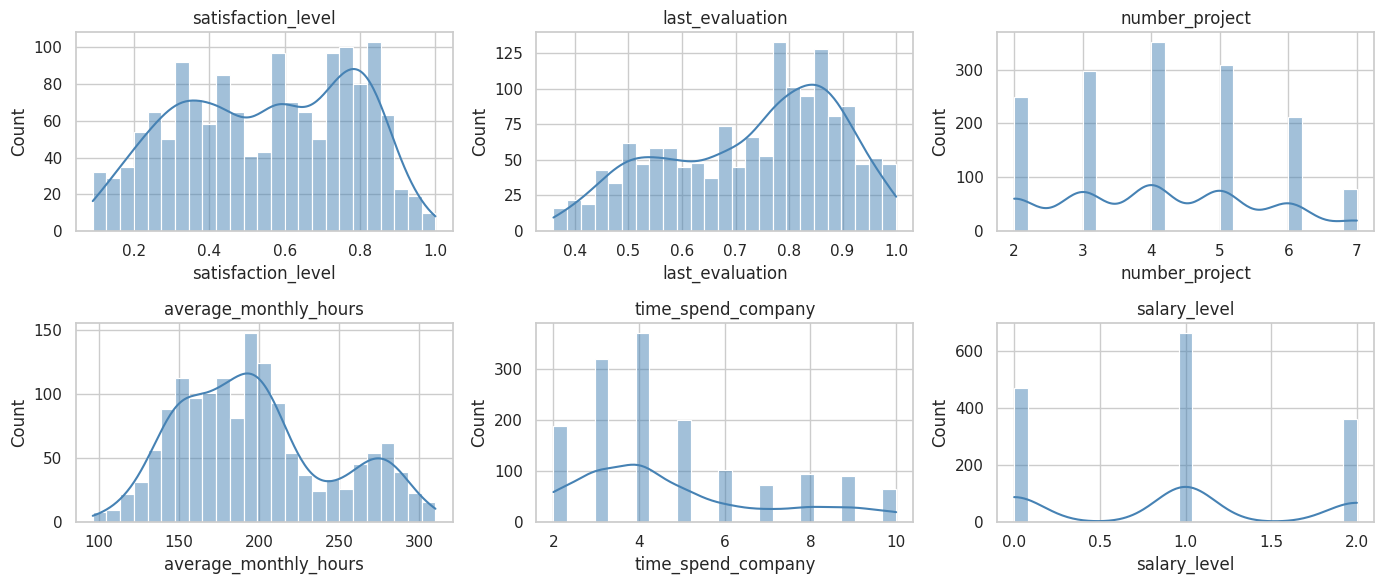

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, f in zip(ax.ravel(), PROFILE_COLS):
    sns.histplot(df[f], bins=25, kde=True, ax=a, color='steelblue')
    a.set_title(f)
plt.tight_layout(); plt.show()

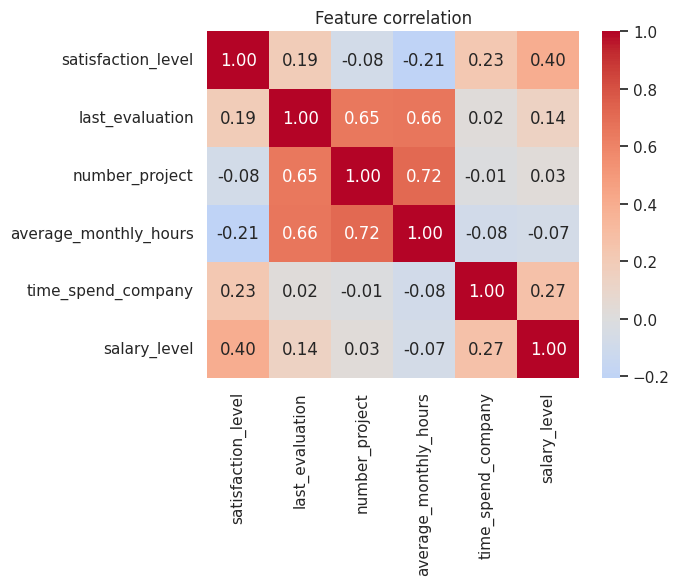

In [5]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[PROFILE_COLS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlation'); plt.show()

### 3. 2D view for plotting (PCA)
The data is already **cleaned and scaled in step 1**, so no preprocessing is needed here. PCA is used **only to draw** the clusters in 2D (the clustering itself uses all features).

In [6]:
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
print('Variance explained by the 2 plotted components:', (pca.explained_variance_ratio_.sum() * 100).round(1), '%')

Variance explained by the 2 plotted components: 72.9 %


### 4. Why K-Means++? Compare with random initialization
30 runs of each (one start per run). K-Means++ gives a lower (better) inertia more consistently and needs fewer iterations.

inertia                           n_iter              
              mean     std      min      max   mean   std min max
init                                                             
k-means++  1875.75    0.01  1875.74  1875.75   4.57  0.94   3   7
random     2165.33  496.81  1875.74  3264.95   9.33  5.35   5  27

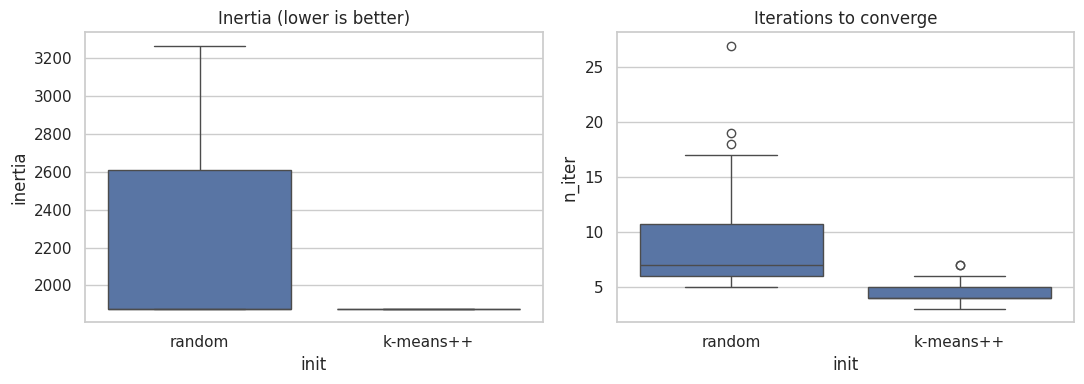

In [7]:
from sklearn.cluster import KMeans

rows = []
for seed in range(30):
    for init in ['random', 'k-means++']:
        km = KMeans(n_clusters=4, init=init, n_init=1, random_state=seed).fit(X)
        rows.append({'init': init, 'inertia': km.inertia_, 'n_iter': km.n_iter_})
init_df = pd.DataFrame(rows)
display(init_df.groupby('init').agg(['mean', 'std', 'min', 'max']).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=init_df, x='init', y='inertia', ax=ax[0]); ax[0].set_title('Inertia (lower is better)')
sns.boxplot(data=init_df, x='init', y='n_iter', ax=ax[1]); ax[1].set_title('Iterations to converge')
plt.tight_layout(); plt.show()

### 5. Choose the number of clusters k
We try k = 2 to 10 and look at 4 measures:
- **Inertia** (elbow method): total squared distance to the centers; always falls when k grows, look for the **elbow** where the fall slows down.
- **Silhouette** (-1 to 1, **higher** is better): how well each point fits its own cluster compared with the nearest other cluster.
- **Calinski-Harabasz** (**higher** is better): between-cluster spread / within-cluster spread.
- **Davies-Bouldin** (**lower** is better): average similarity of every cluster with its most similar cluster.

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,4885.499,0.330,797.530,1.325
3,2917.617,0.441,1171.455,0.862
4,1875.739,0.474,1490.560,0.849
5,1753.150,0.391,1221.389,1.180
6,1644.658,0.347,1060.555,1.422
7,1567.846,0.341,938.648,1.437
8,1516.798,0.267,838.239,1.735
9,1460.366,0.173,768.482,1.925
10,1413.769,0.161,710.585,1.885


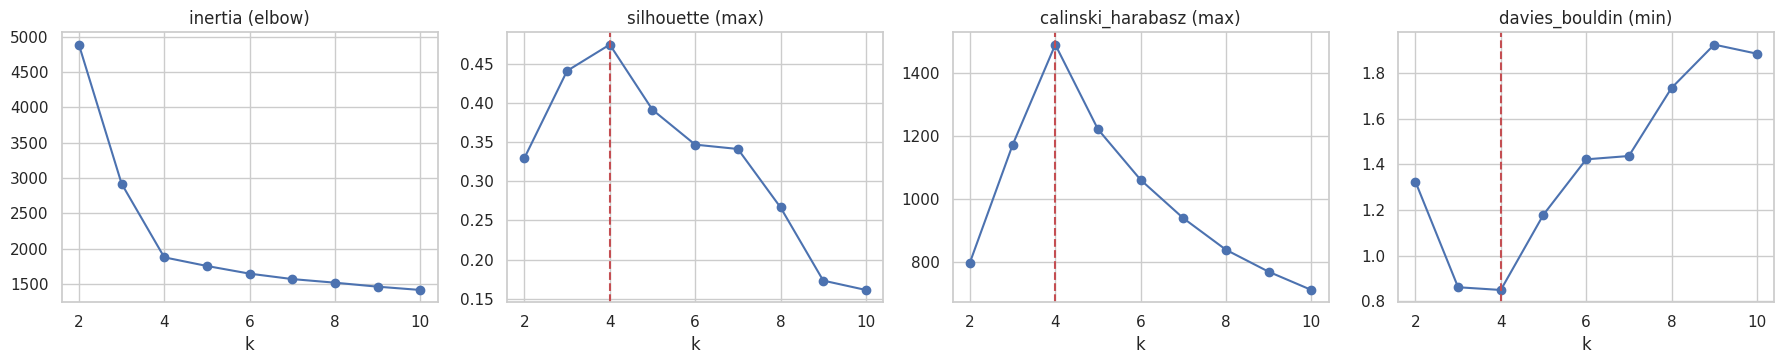

Elbow k          : 4
Best k silhouette: 4
Best k Calinski  : 4
Best k Davies-B. : 4


In [8]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42).fit(X)
    m = internal_metrics(X, km.labels_)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': m['silhouette'],
                 'calinski_harabasz': m['calinski_harabasz'], 'davies_bouldin': m['davies_bouldin']})
k_df = pd.DataFrame(rows).set_index('k')
display(k_df.round(3))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a, col, better in zip(ax, k_df.columns, ['elbow', 'max', 'max', 'min']):
    a.plot(k_df.index, k_df[col], 'o-')
    a.set_title(f'{col} ({better})'); a.set_xlabel('k')
    if better == 'max': a.axvline(k_df[col].idxmax(), color='r', ls='--')
    if better == 'min': a.axvline(k_df[col].idxmin(), color='r', ls='--')
plt.tight_layout(); plt.show()

# elbow point = the point furthest from the straight line between first and last inertia
x_, y_ = np.arange(len(k_df)), k_df['inertia'].values
d = np.abs((y_[-1] - y_[0]) * x_ - (len(k_df) - 1) * (y_ - y_[0])) / np.hypot(y_[-1] - y_[0], len(k_df) - 1)
print('Elbow k          :', k_df.index[d.argmax()])
print('Best k silhouette:', k_df['silhouette'].idxmax())
print('Best k Calinski  :', k_df['calinski_harabasz'].idxmax())
print('Best k Davies-B. :', k_df['davies_bouldin'].idxmin())

### 6. Final K-Means++ model
We use the k with the best **silhouette** (change `best_k` if you prefer another k).

In [9]:
best_k = int(k_df['silhouette'].idxmax())

kmeans = KMeans(n_clusters=best_k, init='k-means++', n_init=20, random_state=42).fit(X)
labels = kmeans.labels_
print('k =', best_k, '| inertia =', round(kmeans.inertia_, 1), '| iterations =', kmeans.n_iter_)
print(pd.Series(labels).value_counts().sort_index().rename('employees').to_string())

k = 4 | inertia = 1875.7 | iterations = 6
0    302
1    372
2    372
3    452


### 7. Evaluation metrics

In [10]:
metrics = internal_metrics(X, labels)
print('===== INTERNAL METRICS (no true labels needed) =====')
print('Silhouette         :', round(metrics['silhouette'], 4), ' (higher is better, > 0.5 = good structure)')
print('Calinski-Harabasz  :', round(metrics['calinski_harabasz'], 1), ' (higher is better)')
print('Davies-Bouldin     :', round(metrics['davies_bouldin'], 4), ' (lower is better)')
print('Inertia            :', round(kmeans.inertia_, 1))

if HAS_TRUTH:
    ext = external_metrics(df['segment_true'], labels)
    print('\n===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====')
    for k_, v_ in ext.items():
        print(f'{k_:<13}: {v_:.4f}')
    print('(ARI / NMI: 1 = perfect match, 0 = random. The 3% outliers cannot be matched by K-Means.)')

===== INTERNAL METRICS (no true labels needed) =====
Silhouette         : 0.4743  (higher is better, > 0.5 = good structure)
Calinski-Harabasz  : 1490.6  (higher is better)
Davies-Bouldin     : 0.8495  (lower is better)
Inertia            : 1875.7

===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====
ARI          : 0.9010
NMI          : 0.8719
homogeneity  : 0.8441
completeness : 0.9015
v_measure    : 0.8719
(ARI / NMI: 1 = perfect match, 0 = random. The 3% outliers cannot be matched by K-Means.)


**Silhouette diagram:** one bar block per cluster. A wide block with bars longer than the average line (red) = a good cluster. Negative bars = employees that probably sit in the wrong cluster.

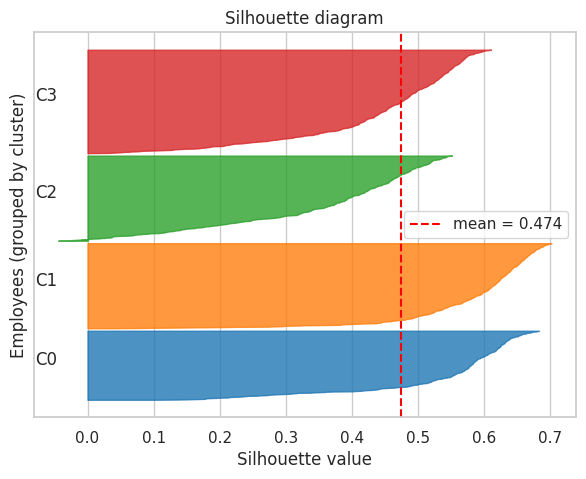

Employees with a negative silhouette: 7 (0.5%)


In [11]:
sil = silhouette_samples(X, labels)
fig, ax = plt.subplots(figsize=(7, 5))
y_low = 10
for c in range(best_k):
    s = np.sort(sil[labels == c])
    ax.fill_betweenx(np.arange(y_low, y_low + len(s)), 0, s, alpha=0.8, color=sns.color_palette('tab10')[c])
    ax.text(-0.08, y_low + len(s) / 2, f'C{c}')
    y_low += len(s) + 10
ax.axvline(metrics['silhouette'], color='red', ls='--', label=f"mean = {metrics['silhouette']:.3f}")
ax.set_xlabel('Silhouette value'); ax.set_ylabel('Employees (grouped by cluster)'); ax.set_yticks([])
ax.set_title('Silhouette diagram'); ax.legend(); plt.show()

print('Employees with a negative silhouette:', int((sil < 0).sum()), f'({(sil < 0).mean() * 100:.1f}%)')

### 8. Stability: do we get the same clusters again?
- **Seed stability:** run K-Means with 10 different random starts and compare with the final labels (ARI).
- **Bootstrap stability:** fit on a random 80% of the employees, predict all employees, compare with the final labels (ARI).
ARI close to 1 = stable clusters.

In [12]:
seed_ari = [adjusted_rand_score(labels, KMeans(best_k, init='k-means++', n_init=1, random_state=s).fit(X).labels_) for s in range(10)]

rng = np.random.default_rng(0)
boot_ari = []
for _ in range(20):
    idx = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    boot_ari.append(adjusted_rand_score(labels, KMeans(best_k, init='k-means++', n_init=10, random_state=1).fit(X[idx]).predict(X)))

print(f'Seed stability     (ARI): mean {np.mean(seed_ari):.3f} | min {np.min(seed_ari):.3f}')
print(f'Bootstrap stability (ARI): mean {np.mean(boot_ari):.3f} | min {np.min(boot_ari):.3f}')

Seed stability     (ARI): mean 0.999 | min 0.998
Bootstrap stability (ARI): mean 0.997 | min 0.988


### 9. Visualization

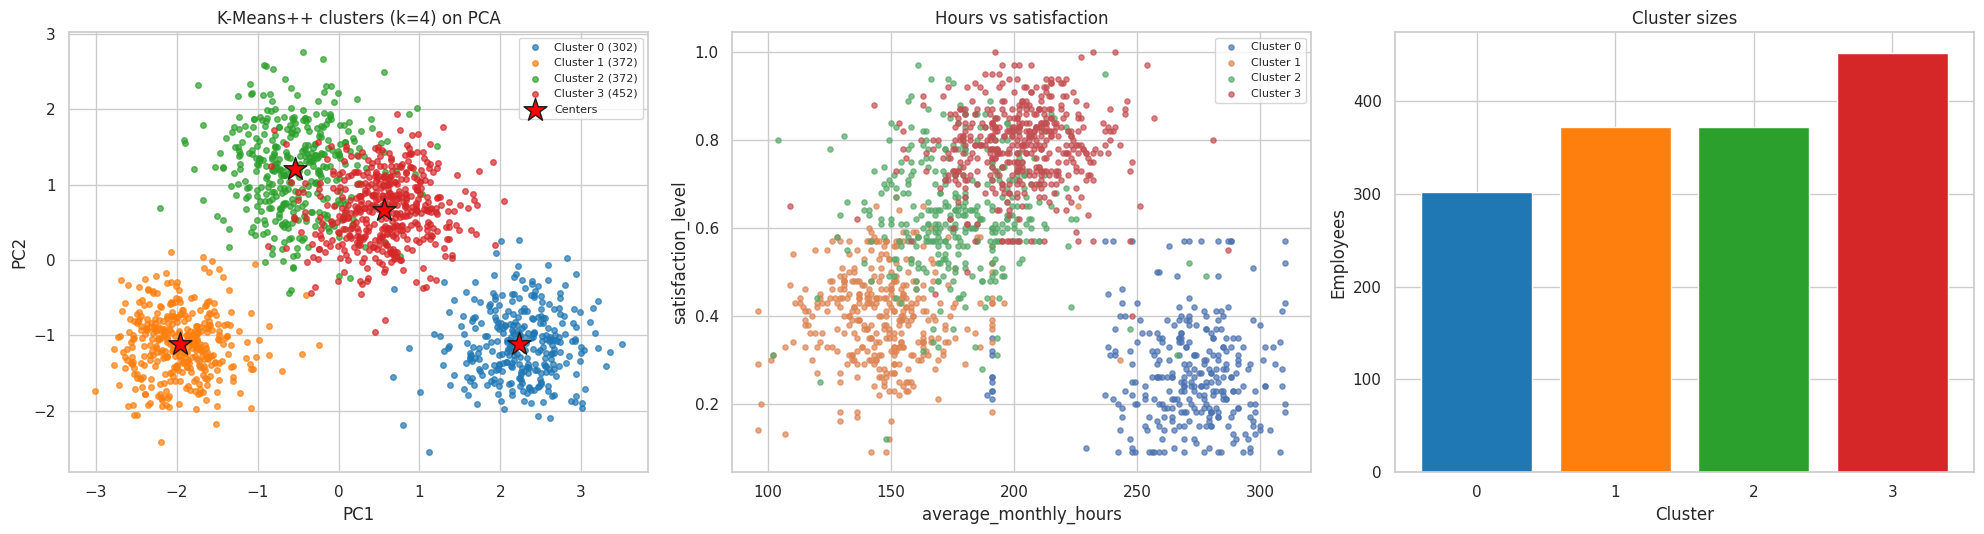

In [13]:
centers_pca = pca.transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
plot_clusters(Z, labels, ax[0], f'K-Means++ clusters (k={best_k}) on PCA', centers=centers_pca)

# the two most meaningful HR features
for c in range(best_k):
    m = labels == c
    ax[1].scatter(df.loc[m, 'average_monthly_hours'], df.loc[m, 'satisfaction_level'], s=14, alpha=0.7, label=f'Cluster {c}')
ax[1].set_xlabel('average_monthly_hours'); ax[1].set_ylabel('satisfaction_level'); ax[1].set_title('Hours vs satisfaction'); ax[1].legend(fontsize=8)

sizes = pd.Series(labels).value_counts().sort_index()
ax[2].bar(sizes.index.astype(str), sizes.values, color=sns.color_palette('tab10')[:best_k])
ax[2].set_xlabel('Cluster'); ax[2].set_ylabel('Employees'); ax[2].set_title('Cluster sizes')
plt.tight_layout(); plt.show()

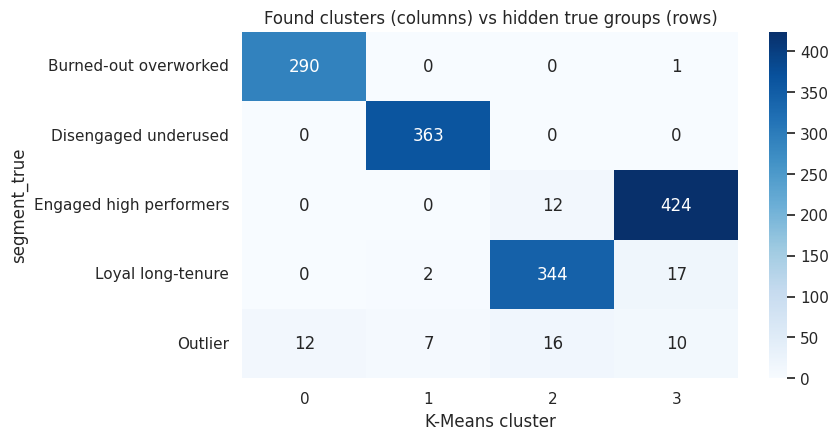

In [14]:
if HAS_TRUTH:
    plt.figure(figsize=(8, 4.5))
    sns.heatmap(pd.crosstab(df['segment_true'], labels), annot=True, fmt='d', cmap='Blues')
    plt.title('Found clusters (columns) vs hidden true groups (rows)'); plt.xlabel('K-Means cluster'); plt.show()

### 10. Cluster profile: who is in each cluster?
This is the most useful output for HR. The heatmap shows, for each cluster, which features are high (green) or low (red) compared with the other clusters.

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,size,share_%
cluster,,,,,,,,
0,0.27,0.87,5.98,270.61,3.92,0.53,302,20.2
1,0.40,0.52,2.46,147.11,3.16,0.53,372,24.8
2,0.64,0.70,3.79,178.71,8.08,1.31,372,24.8
3,0.79,0.84,4.49,202.84,3.90,1.21,452,30.2


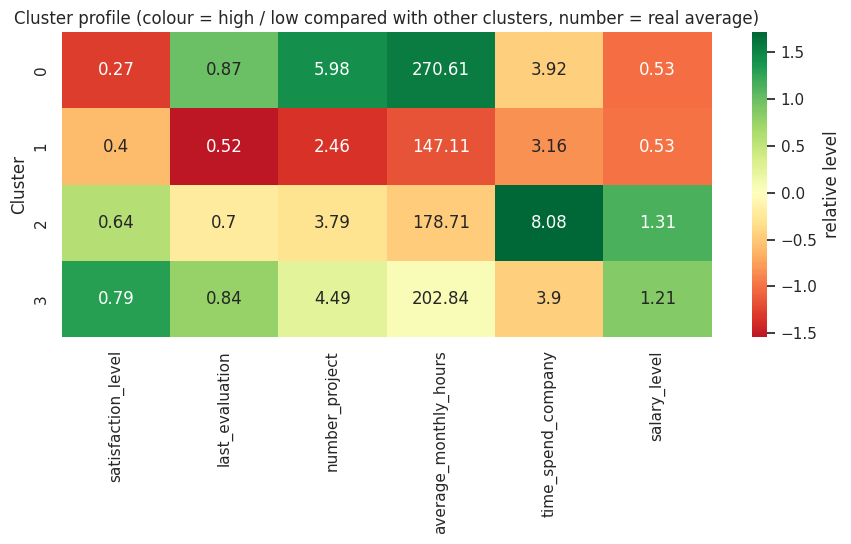

In [15]:
prof = cluster_profile(df, labels)
display(prof.round(2))
plot_profile(prof)

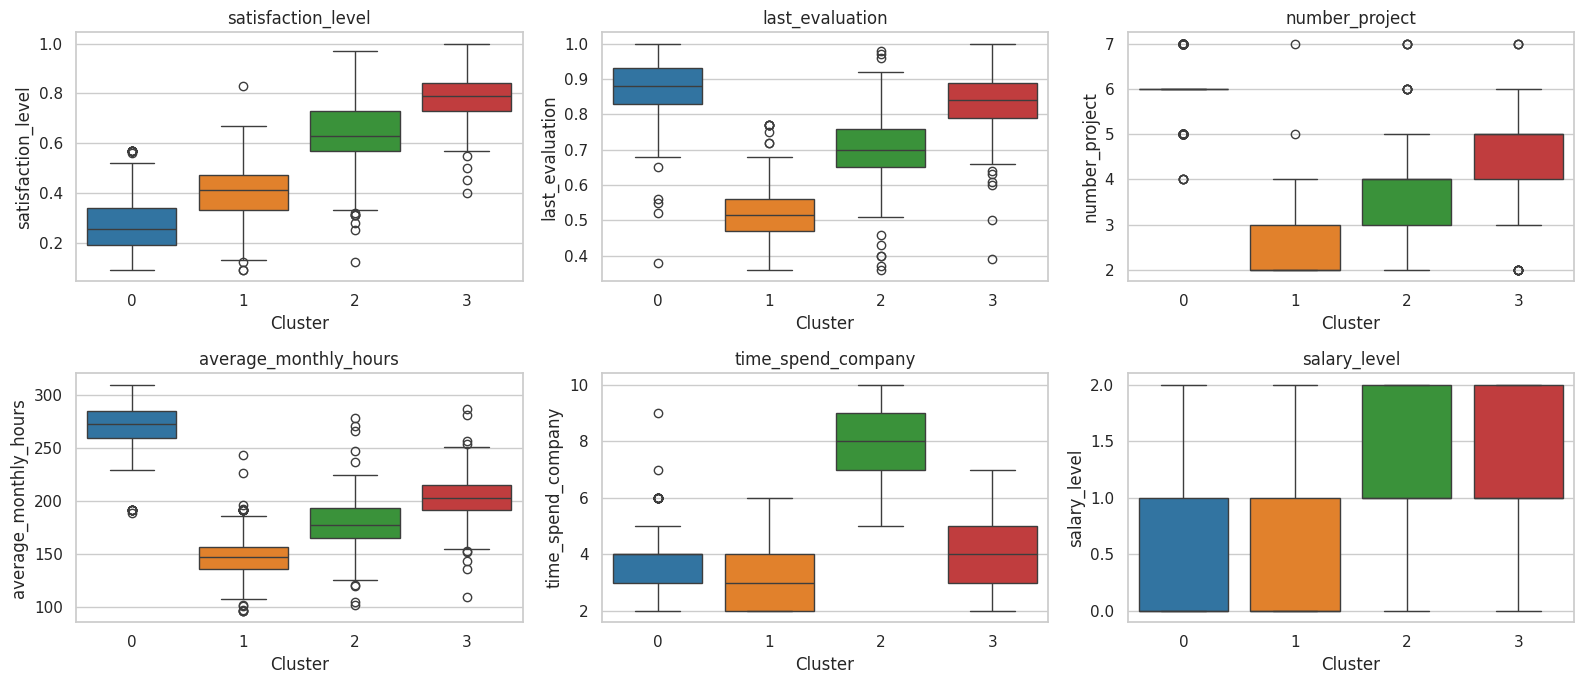

In [16]:
# distribution of each feature per cluster
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for a, f in zip(ax.ravel(), PROFILE_COLS):
    sns.boxplot(x=labels, y=df[f], ax=a, palette='tab10'); a.set_title(f); a.set_xlabel('Cluster')
plt.tight_layout(); plt.show()

### 11. Predict the cluster of new employees and save the model
K-Means can assign **new** employees to a cluster (`predict`).

In [17]:
new = pd.DataFrame({'satisfaction_level': [0.15, 0.85, 0.45], 'last_evaluation': [0.90, 0.88, 0.50],
                    'number_project': [7, 5, 2], 'average_monthly_hours': [280, 210, 140],
                    'time_spend_company': [4, 3, 3]})
new['cluster'] = kmeans.predict(scaler.transform(new[FEATURES]))
display(new)

joblib.dump({'scaler': scaler, 'model': kmeans, 'features': FEATURES, 'profile': prof}, 'kmeans_hr_model.pkl')
df.assign(cluster=labels).to_csv('hr_kmeans_clusters.csv', index=False)
print('Saved: kmeans_hr_model.pkl, hr_kmeans_clusters.csv')

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,cluster
0,0.15,0.90,7,280,4,0
1,0.85,0.88,5,210,3,3
2,0.45,0.50,2,140,3,1


Saved: kmeans_hr_model.pkl, hr_kmeans_clusters.csv


### 12. Download (Google Colab only)

In [18]:
try:
    from google.colab import files
    files.download('kmeans_hr_model.pkl'); files.download('hr_kmeans_clusters.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
